<a href="https://colab.research.google.com/github/Apurba213/Ostad_AI-Ml-engineering-course/blob/main/Module15_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#import libraries
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import fashion_mnist
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)


# Part A: Data Preparation
We load Fashion-MNIST, look at 10 sample images, normalise pixels to [0, 1] and create **train / validation / test** splits.

In [ ]:
# Load the data (60,000 train + 10,000 test images)
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print("Full training set:", X_train_full.shape, y_train_full.shape)
print("Test set:         ", X_test.shape, y_test.shape)
print("Pixel range before normalisation:", X_train_full.min(), "-", X_train_full.max())

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Full training set: (60000, 28, 28) (60000,)
Test set:          (10000, 28, 28) (10000,)
Pixel range before normalisation: 0 - 255


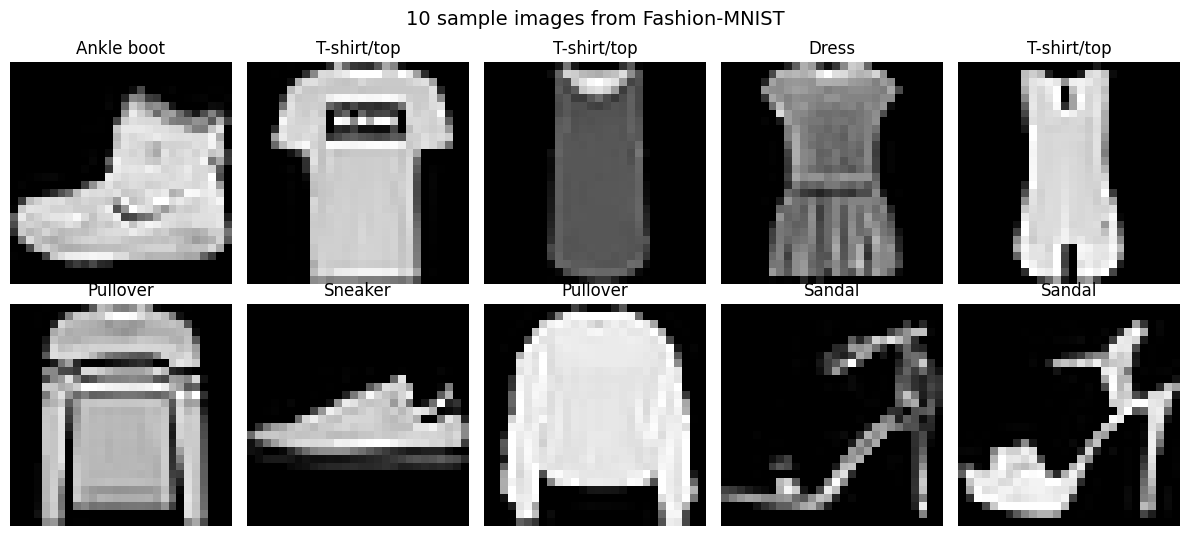

In [ ]:
# Display 10 sample images with their labels
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train_full[i], cmap='gray')
    ax.set_title(class_names[y_train_full[i]])
    ax.axis('off')
plt.suptitle("10 sample images from Fashion-MNIST", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# 1) Normalise pixel values from 0-255 to 0-1
X_train_full = X_train_full.astype("float32") / 255.0
X_test       = X_test.astype("float32") / 255.0

# 2) Add a channel dimension -> (N, 28, 28, 1). The CNN needs it; the dense net just flattens it.
X_train_full = X_train_full[..., np.newaxis]
X_test       = X_test[..., np.newaxis]

# 3) Train / validation split (90% / 10%), stratified so every class is equally represented
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.10, stratify=y_train_full, random_state=SEED)

print("Pixel range after normalisation:", X_train.min(), "-", X_train.max())
print(f"Train: {X_train.shape[0]} | Validation: {X_val.shape[0]} | Test: {X_test.shape[0]}")

Pixel range after normalisation: 0.0 - 1.0
Train: 54000 | Validation: 6000 | Test: 10000


# Part B: Baseline Neural Network (Fully Connected)
Architecture:Flatten → Dense(512, ReLU) → Dense(256, ReLU) → Dense(10, Softmax)

Loss:sparse_categorical_crossentropy`, the right choice for multi-class classification with integer labels and a softmax output.
Optimizer:Adam, which adapts the learning rate per weight and works well with little tuning.

In [ ]:
dense_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),                       # 28*28*1 = 784 numbers; spatial structure is thrown away
    layers.Dense(512, activation='relu'),
    layers.Dense(256, activation='relu'),
    layers.Dense(10, activation='softmax')  # probabilities over 10 classes
], name="dense_baseline")

dense_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                    loss='sparse_categorical_crossentropy',
                    metrics=['accuracy'])
dense_model.summary()

Model: "dense_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 535,818 (2.04 MB)

 Trainable params: 535,818 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_dense = dense_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20, batch_size=128, verbose=2)

Epoch 1/20
422/422 - 6s - 14ms/step - accuracy: 0.8204 - loss: 0.5014 - val_accuracy: 0.8568 - val_loss: 0.4095
Epoch 2/20
422/422 - 1s - 3ms/step - accuracy: 0.8672 - loss: 0.3640 - val_accuracy: 0.8720 - val_loss: 0.3517
Epoch 3/20
422/422 - 1s - 3ms/step - accuracy: 0.8825 - loss: 0.3221 - val_accuracy: 0.8753 - val_loss: 0.3382
Epoch 4/20
422/422 - 1s - 3ms/step - accuracy: 0.8894 - loss: 0.2976 - val_accuracy: 0.8817 - val_loss: 0.3225
Epoch 5/20
422/422 - 1s - 3ms/step - accuracy: 0.8960 - loss: 0.2782 - val_accuracy: 0.8918 - val_loss: 0.2997
Epoch 6/20
422/422 - 1s - 3ms/step - accuracy: 0.9014 - loss: 0.2609 - val_accuracy: 0.8908 - val_loss: 0.2963
Epoch 7/20
422/422 - 1s - 3ms/step - accuracy: 0.9069 - loss: 0.2449 - val_accuracy: 0.8875 - val_loss: 0.3108
Epoch 8/20
422/422 - 1s - 3ms/step - accuracy: 0.9120 - loss: 0.2341 - val_accuracy: 0.8895 - val_loss: 0.3078
Epoch 9/20
422/422 - 2s - 4ms/step - accuracy: 0.9158 - loss: 0.2227 - val_accuracy: 0.8928 - val_loss: 0.2989


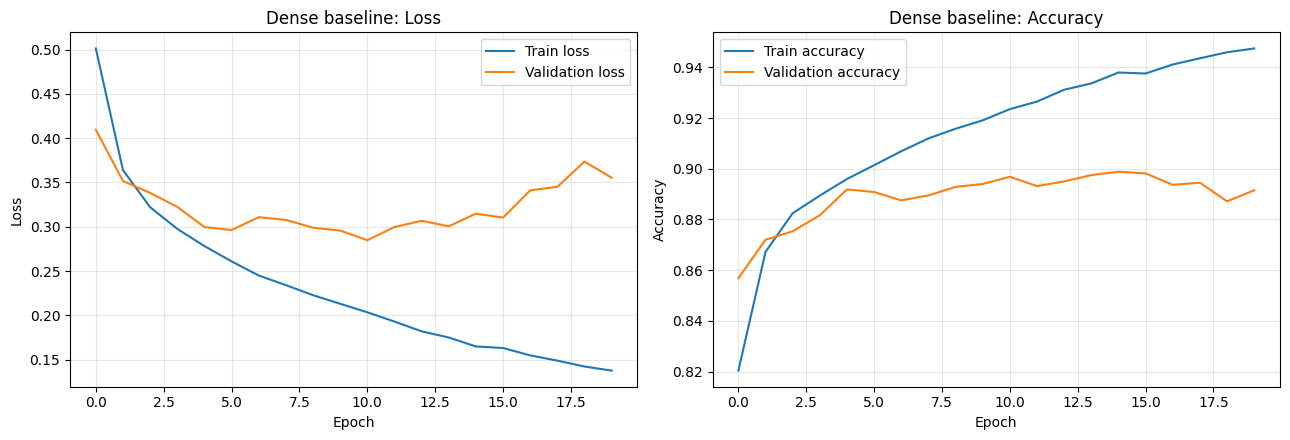

In [ ]:
def plot_history(history, title):
    """Plot training vs. validation loss and accuracy."""
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].plot(history.history['loss'], label='Train loss')
    ax[0].plot(history.history['val_loss'], label='Validation loss')
    ax[0].set_title(f'{title}: Loss'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss'); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(history.history['accuracy'], label='Train accuracy')
    ax[1].plot(history.history['val_accuracy'], label='Validation accuracy')
    ax[1].set_title(f'{title}: Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy'); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

plot_history(history_dense, "Dense baseline")

# Part C: Convolutional Neural Network
**Architecture**
- Data augmentation (random horizontal flip + small shifts; only active during training)
- Block 1: Conv2D(32) → BatchNorm → Conv2D(32) → BatchNorm → MaxPool → Dropout(0.25)
- Block 2: Conv2D(64) → BatchNorm → Conv2D(64) → BatchNorm → MaxPool → Dropout(0.25)
- Flatten → Dense(64, ReLU) → Dropout(0.4) → Dense(10, Softmax)

Overfitting controls:Batch Normalization, Dropout, light data augmentation, early stopping and learning-rate reduction on plateau.

In [ ]:
def conv_block(filters, dropout):
    return [
        layers.Conv2D(filters, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(filters, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2),
        layers.Dropout(dropout),
    ]

cnn_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    # Data augmentation (automatically disabled at validation/test time)
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.08, 0.08),

    *conv_block(32, 0.25),   # 28x28 -> 14x14
    *conv_block(64, 0.25),   # 14x14 -> 7x7

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(10, activation='softmax')
], name="cnn")

cnn_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
cnn_model.summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 266,986 (1.02 MB)

 Trainable params: 266,602 (1.02 MB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5, verbose=1),
]

history_cnn = cnn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40, batch_size=128, callbacks=callbacks, verbose=2)

Epoch 1/40
422/422 - 17s - 39ms/step - accuracy: 0.6212 - loss: 1.0185 - val_accuracy: 0.5502 - val_loss: 1.2232 - learning_rate: 0.0010
Epoch 2/40
422/422 - 8s - 19ms/step - accuracy: 0.7328 - loss: 0.6941 - val_accuracy: 0.8438 - val_loss: 0.4247 - learning_rate: 0.0010
Epoch 3/40
422/422 - 8s - 19ms/step - accuracy: 0.7573 - loss: 0.6216 - val_accuracy: 0.8593 - val_loss: 0.3761 - learning_rate: 0.0010
Epoch 4/40
422/422 - 8s - 19ms/step - accuracy: 0.7712 - loss: 0.5913 - val_accuracy: 0.8655 - val_loss: 0.3790 - learning_rate: 0.0010
Epoch 5/40
422/422 - 8s - 19ms/step - accuracy: 0.7811 - loss: 0.5645 - val_accuracy: 0.8785 - val_loss: 0.3336 - learning_rate: 0.0010
Epoch 6/40
422/422 - 8s - 19ms/step - accuracy: 0.7981 - loss: 0.5264 - val_accuracy: 0.8798 - val_loss: 0.3238 - learning_rate: 0.0010
Epoch 7/40
422/422 - 8s - 19ms/step - accuracy: 0.8087 - loss: 0.5024 - val_accuracy: 0.8913 - val_loss: 0.3014 - learning_rate: 0.0010
Epoch 8/40
422/422 - 8s - 20ms/step - accuracy:

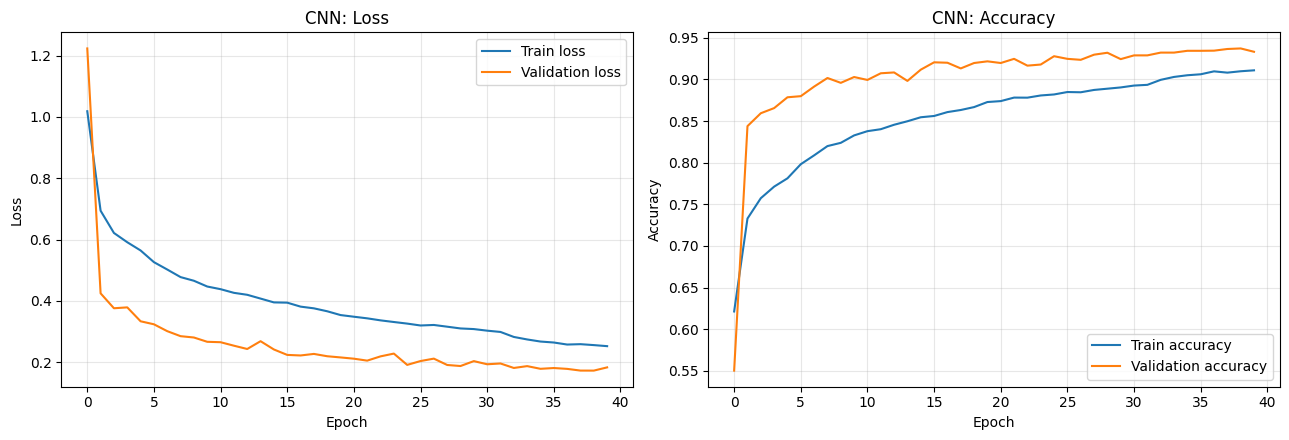

In [ ]:
plot_history(history_cnn, "CNN")

# Part D: Evaluation and Comparison

Model               Test accuracy   Test loss    Trainable params
-----------------------------------------------------------------
Dense baseline             0.8793      0.4216             535,818
CNN                        0.9280      0.2066             266,602


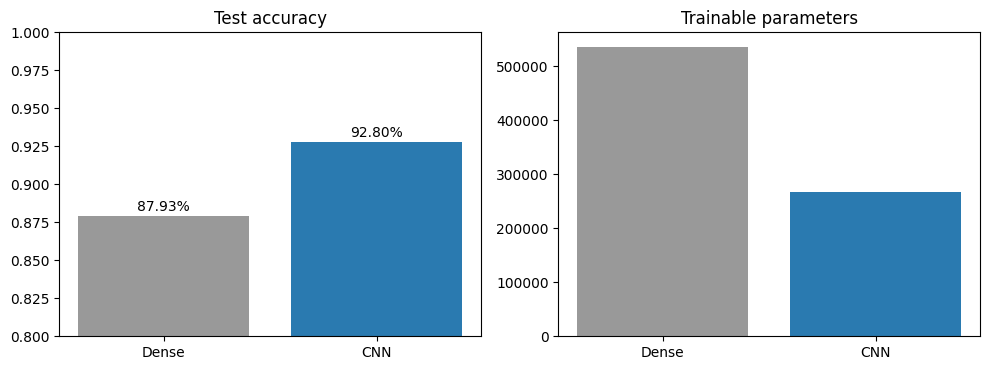

In [ ]:
# --- Test accuracy and trainable parameters for both models ---
def count_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

dense_loss, dense_acc = dense_model.evaluate(X_test, y_test, verbose=0)
cnn_loss,   cnn_acc   = cnn_model.evaluate(X_test, y_test, verbose=0)

print(f"{'Model':<18}{'Test accuracy':>15}{'Test loss':>12}{'Trainable params':>20}")
print("-" * 65)
print(f"{'Dense baseline':<18}{dense_acc:>15.4f}{dense_loss:>12.4f}{count_trainable(dense_model):>20,}")
print(f"{'CNN':<18}{cnn_acc:>15.4f}{cnn_loss:>12.4f}{count_trainable(cnn_model):>20,}")

# Bar chart
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].bar(['Dense', 'CNN'], [dense_acc, cnn_acc], color=['#999', '#2a7ab0'])
ax[0].set_ylim(0.8, 1.0); ax[0].set_title('Test accuracy')
for i, v in enumerate([dense_acc, cnn_acc]): ax[0].text(i, v + .003, f"{v:.2%}", ha='center')
ax[1].bar(['Dense', 'CNN'], [count_trainable(dense_model), count_trainable(cnn_model)], color=['#999', '#2a7ab0'])
ax[1].set_title('Trainable parameters')
plt.tight_layout(); plt.show()

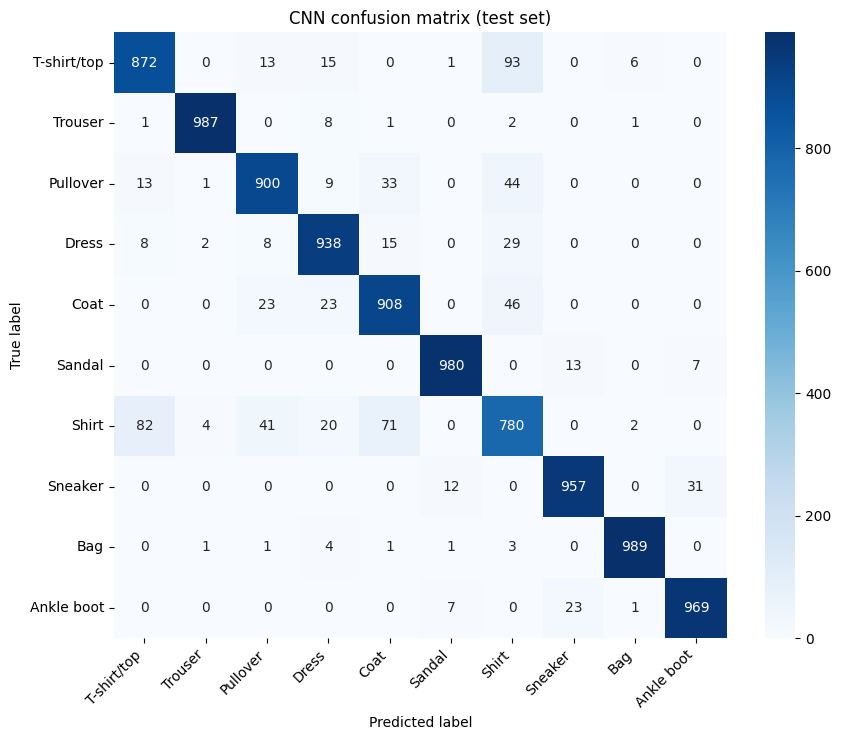

              precision    recall  f1-score   support

 T-shirt/top      0.893     0.872     0.883      1000
     Trouser      0.992     0.987     0.989      1000
    Pullover      0.913     0.900     0.906      1000
       Dress      0.922     0.938     0.930      1000
        Coat      0.882     0.908     0.895      1000
      Sandal      0.979     0.980     0.980      1000
       Shirt      0.782     0.780     0.781      1000
     Sneaker      0.964     0.957     0.960      1000
         Bag      0.990     0.989     0.989      1000
  Ankle boot      0.962     0.969     0.966      1000

    accuracy                          0.928     10000
   macro avg      0.928     0.928     0.928     10000
weighted avg      0.928     0.928     0.928     10000



In [ ]:
# --- Confusion matrix for the CNN ---
y_prob = cnn_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9, 7.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted label'); plt.ylabel('True label'); plt.title('CNN confusion matrix (test set)')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

In [ ]:
# Most frequently confused class pairs (off-diagonal entries)
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
pairs = [(cm_off[i, j], class_names[i], class_names[j]) for i in range(10) for j in range(10) if cm_off[i, j] > 0]
print("Top confusions (count, true -> predicted):")
for n, t, p in sorted(pairs, reverse=True)[:6]:
    print(f"  {n:>4}  {t} -> {p}")

Top confusions (count, true -> predicted):
    93  T-shirt/top -> Shirt
    82  Shirt -> T-shirt/top
    71  Shirt -> Coat
    46  Coat -> Shirt
    44  Pullover -> Shirt
    41  Shirt -> Pullover


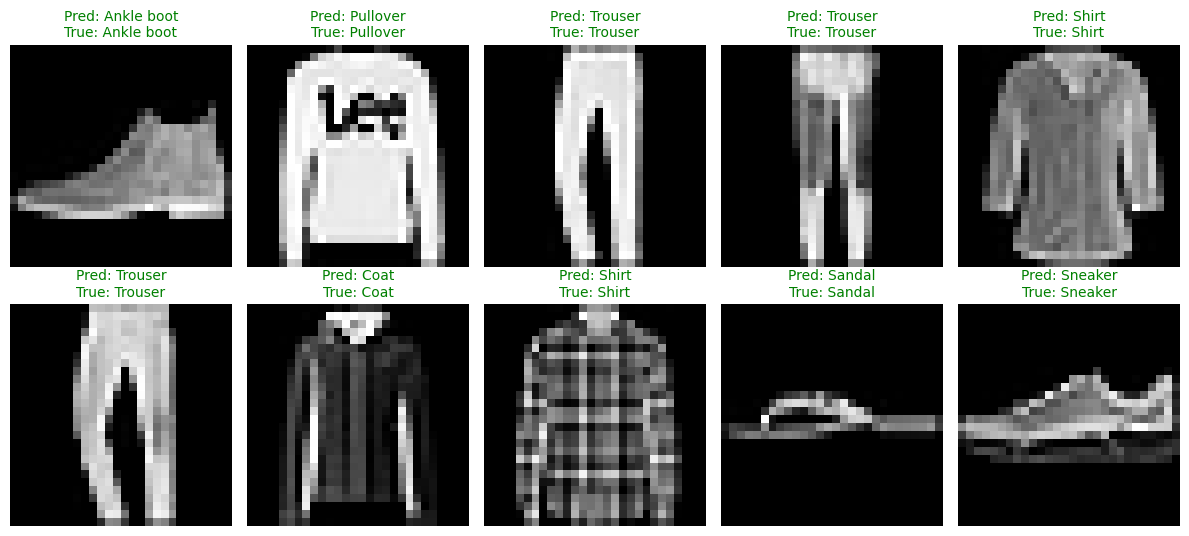

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_test[i].squeeze(), cmap='gray')
    ok = y_pred[i] == y_test[i]
    ax.set_title(f"Pred: {class_names[y_pred[i]]}\nTrue: {class_names[y_test[i]]}", color='green' if ok else 'red', fontsize=10)
    ax.axis('off')
plt.tight_layout(); plt.show()

Total misclassified: 720 of 10000


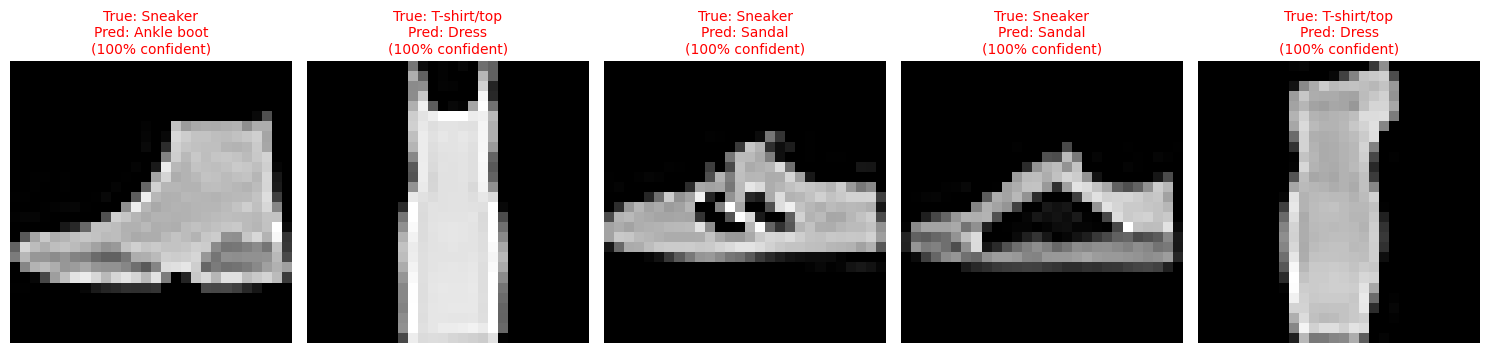

In [ ]:
wrong = np.where(y_pred != y_test)[0]
conf  = y_prob[wrong, y_pred[wrong]]
worst5 = wrong[np.argsort(-conf)[:5]]

print(f"Total misclassified: {len(wrong)} of {len(y_test)}")
fig, axes = plt.subplots(1, 5, figsize=(15, 3.8))
for ax, idx in zip(axes, worst5):
    ax.imshow(X_test[idx].squeeze(), cmap='gray')
    ax.set_title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[y_pred[idx]]}\n({y_prob[idx, y_pred[idx]]:.0%} confident)", color='red', fontsize=10)
    ax.axis('off')
plt.tight_layout(); plt.show()

### Why did the CNN fail on these images?
The confusion matrix shows that nearly all errors fall inside one visually similar group of upper-body clothing:Shirt,T-shirt/top,Pullover and Coat. Typical reasons for the mistakes above:

- Shirt ↔ T-shirt/top:at 28×28 resolution the only differences are collars, buttons and sleeve length, which are only a few pixels.A long-sleeved "T-shirt" looks almost identical to a shirt.
- Pullover ↔ Coat:** both have long sleeves and a similar silhouette; zippers and buttons that distinguish a coat vanish at this resolution.
- Ambiguous or unusual items:** some images are mislabelled-looking or photographed in an unusual way (folded, cropped, low contrast), so even a human would hesitate.
- Low resolution + grayscale:** colour and fine texture, which would help separate these classes, are not available.



# Part E: Reflection

Why does the CNN outperform the dense network, even with fewer parameters?
The dense network flattens each image into 784 numbers, so it has no idea that two pixels are neighbours. Every pixel gets its own weight to every neuron, and the network must learn separately that a sleeve edge at the top-left means the same as one at the bottom-right.A CNN builds in three assumptions that fit images.First,local connectivity: each filter looks at a small 3×3 patch, so it learns edges, corners and textures. Second, weight sharing: the same filter slides across the entire image, so one small set of weights detects a feature anywhere, which is why the CNN needs fewer parameters. Third,hierarchy: pooling shrinks the image while stacked layers combine edges into parts and parts into whole garments, giving some tolerance to small shifts. These priors make better use of each parameter, so the CNN generalises better with fewer weights.

What did I observe about overfitting?
The dense baseline overfits clearly. Its training accuracy keeps climbing while validation loss stops improving and starts rising, so it memorises the training set. The CNN was regularised with Batch Normalization, Dropout, light data augmentation, early stopping and learning-rate reduction, and its training and validation curves stay much closer together. Its validation accuracy is also higher. Augmentation and dropout make the training metrics look slightly worse than validation early on, which is expected, since both are active only during training.

What would I try next?
(1) A deeper architecture such as a small ResNet, or a third convolutional block. (2) Stronger augmentation (random erasing, small rotations, MixUp or CutMix). (3) Tuning hyper-parameters such as learning rate, batch size and dropout rate, with a learning-rate schedule like cosine decay. (4) An ensemble of several CNNs trained with different seeds, which usually adds a little accuracy. (5) Transfer learning with a pre-trained network on upscaled images, to help the hardest classes (Shirt, T-shirt, Pullover, Coat). (6) Moving to CIFAR-10, a harder colour dataset, to test whether the same conclusions hold.